#  Industrial Anomaly Detection System
## Using CNN & Transfer Learning on MVTec AD Dataset

---

## 1. Problem Definition

### Problem Statement
> *"Can we automatically detect defects in industrial products 
> using computer vision, replacing manual visual inspection 
> with an AI powered quality control system?"*

### Business Problem
Manual quality inspection in manufacturing is:
-  **Slow** — human inspectors check one item at a time
-  **Expensive** — requires trained personnel 24/7
-  **Inconsistent** — human fatigue causes missed defects
-  **Not scalable** — can't keep up with production speed

### Our Solution
Build a **CNN-based anomaly detection system** that:
-  Automatically classifies products as Normal or Defective
-  Works in real time on production lines
-  Provides visual explanation of WHERE defect is located
-  Deployable as REST API on AWS EC2

---

##  Data

### Dataset — MVTec Anomaly Detection (MVTec AD)
The **industry standard benchmark** for anomaly detection,
used by Mercedes-Benz, Siemens and Bosch in research.

| Property | Value |
|---|---|
| Source | MVTec Software GmbH |
| Type | Real industrial images |
| Categories used | Bottle, Screw, Carpet |
| Total images | ~1,100 |
| Image format | PNG (high resolution) |
| License | Free for academic use |

##  Evaluation Metrics

Since this is a **binary classification** problem:
- Class 0 = Normal 
- Class 1 = Defective 

In [1]:
# Install packages
!pip install torch torchvision matplotlib seaborn scikit-learn --quiet
print("Packages installed!")

Packages installed!


In [2]:

# Plot inside notebook
%matplotlib inline

# Standard Library
import os, sys, random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from collections import Counter

# PyTorch Core
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset

# TorchVision
import torchvision
from torchvision import transforms, models, datasets

# Scikit-Learn Metrics
from sklearn.metrics import (
    accuracy_score, recall_score,
    precision_score, f1_score,
    roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report
)

# AWS
import boto3
import sagemaker

# Device
device = "cuda" if torch.cuda.is_available() else "cpu"

# Seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Constants
BUCKET = "anomaly-detection-mvtec"
DATA_DIR = Path("data/mvtec")
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)
CATEGORIES = ["bottle", "screw", "carpet"]
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 2
NUM_EPOCHS = 10
LEARNING_RATE = 0.001
CLASS_NAMES = ["good", "defective"]

print(f"PyTorch:  {torch.__version__}")
print(f"Device:   {device}")
print(f"Seed:     {SEED}")
print("Master setup complete!")

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/ec2-user/.config/sagemaker/config.yaml


/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/__init__.py:86: SageMakerV2DeprecationWarning: You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation()
You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.


PyTorch:  2.14.1+cu130
Device:   cuda
Seed:     42
Master setup complete!


In [3]:
# Define constants
BUCKET = "anomaly-detection-mvtec"
DATA_DIR = Path("data/mvtec")
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

# Categories
CATEGORIES = ["bottle", "screw", "carpet"]

# Model Settings
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 2
NUM_EPOCHS = 10
LEARNING_RATE = 0.001

# Classes
CLASS_NAMES = ["good", "defective"]

print("Constants defined")
print(f"Categories: {CATEGORIES}")
print(f"Image size: {IMG_SIZE}x{IMG_SIZE}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {NUM_EPOCHS}")
print(f"Device: {device}")

Constants defined
Categories: ['bottle', 'screw', 'carpet']
Image size: 224x224
Batch size: 32
Epochs: 10
Device: cuda


In [4]:
# Download Data from S3
s3 = boto3.client("s3")

for cat in CATEGORIES:
    save_path = DATA_DIR / cat
    save_path.mkdir(parents=True, exist_ok=True)

    print(f"Downloading {cat}")
    os.system(f"aws s3 cp s3://{BUCKET}/data/{cat} {DATA_DIR}/{cat} --recursive --quiet")
    print(f"{cat} downloaded!")

print("\nAll data downloaded!")    

bottle downloaded!
screw downloaded!
carpet downloaded!

All data downloaded!


In [5]:
# Verify Data Structure
print("Dataset Summary:")
print("="*55)

for cat in CATEGORIES:
    base = DATA_DIR / cat
    train_path = base / "train" / "good"
    train_count = len(list(train_path.glob("*.png")))

    test_path = base / "test"
    test_classes = [d.name for d in test_path.iterdir() 
                    if d.is_dir()]
    test_count = sum(
        len(list((test_path / d).glob("*.png")))
        for d in test_classes
    )

    print(f"\n{cat.upper()}")
    print(f"  Train (normal):  {train_count} images")
    print(f"  Test total:      {test_count} images")
    print(f"  Test classes:    {test_classes}")

print("\n" + "="*55)

Dataset Summary:

BOTTLE
  Train (normal):  209 images
  Test total:      83 images
  Test classes:    ['broken_small', 'broken_large', 'contamination', 'good']

SCREW
  Train (normal):  320 images
  Test total:      160 images
  Test classes:    ['thread_side', 'manipulated_front', 'scratch_head', 'thread_top', 'good', 'scratch_neck']

CARPET
  Train (normal):  280 images
  Test total:      117 images
  Test classes:    ['hole', 'metal_contamination', 'thread', 'cut', 'good', 'color']



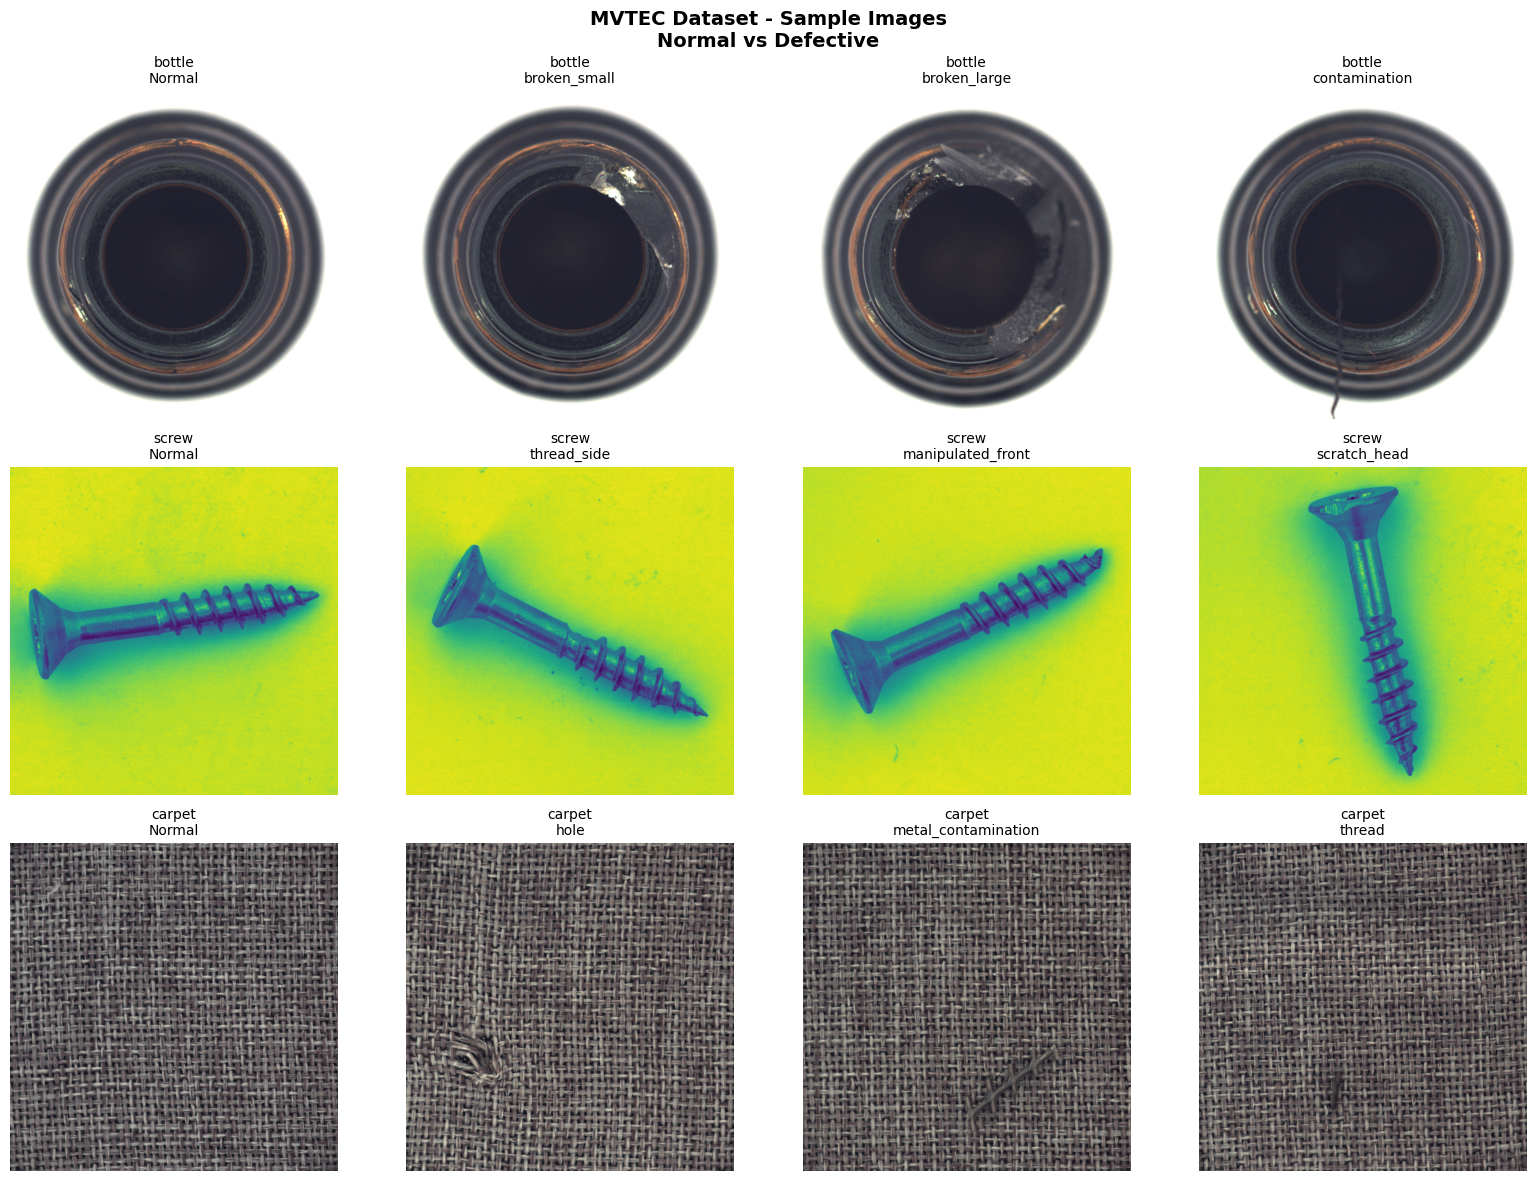

In [6]:
# Visaualize Sample Images
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for row, cat in enumerate(CATEGORIES):
    base = DATA_DIR / cat

    # Normal image
    normal_imgs = list ((base / "train" / "good").glob("*.png"))
    normal_img = Image.open(random.choice(normal_imgs))
    axes[row, 0].imshow(normal_img)
    axes[row, 0].set_title(f"{cat}\nNormal", fontsize=10)
    axes[row, 0].axis("off")

    # Defective images
    test_classes = [d for d in (base / "test").iterdir()
                   if d.is_dir() and d.name != "good"]

    for col, defect_dir in enumerate(test_classes[:3], start=1):
        defect_imgs = list(defect_dir.glob("*.png"))
        if defect_imgs:
            defect_img = Image.open(random.choice(defect_imgs))
            axes[row, col].imshow(defect_img)
            axes[row, col].set_title(
                f"{cat}\n{defect_dir.name}",
                fontsize=10
            )
            axes[row, col].axis("off")
plt.suptitle(
    "MVTEC Dataset - Sample Images\nNormal vs Defective",
    fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.show()

## Data Preprocessing

### Overview
Raw MVTec images need preprocessing before feeding 
into our CNN and Transfer Learning. We apply different transformations 
for training and testing:

### Preprocessing Steps
1. **Resize** — all images to 224×224 pixels
2. **Augmentation** — training only (prevent overfitting)
3. **ToTensor** — convert PIL images to PyTorch tensors
4. **Normalize** — using ImageNet mean and std values

In [7]:
# Data Transforms
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(10), 
    transforms.ColorJitter(
        brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
    
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Transform defined!")
print(f"\nTrain transform: {train_transform}")
print(f"\nTest transformsro: {test_transform}")

Transform defined!

Train transform: Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Test transformsro: Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


### Custom Dataset Class

MVTec has multiple defect folders per category.
We need a custom Dataset class to:
- Combine all defect types into ONE label (defective=1)
- Keep normal images as label 0
- Handle train/test splits correctly

| Split | Images | Label |
|---|---|---|
| Train | good/ only | 0 (normal) |
| Test good/ | good images | 0 (normal) |
| Test defects/ | all defect types | 1 (defective) |

In [8]:
# Custom Data
from sklearn.model_selection import train_test_split

class MVTecDataset(Dataset):
    def __init__(self, root_dir, category,
                 split="train", transform=None):
        self.transform = transform
        self.images = []
        self.labels = []

        base = Path(root_dir) / category

        # All images from the test folder (good = 0, defective = 1)
        t_paths, t_labels = [], []
        for class_dir in sorted((base / "test").iterdir()):
            if class_dir.is_dir():
                label = 0 if class_dir.name == "good" else 1
                for img_path in sorted(class_dir.glob("*.png")):
                    t_paths.append(img_path)
                    t_labels.append(label)

        # 40% train pool | 20% val | 40% test (stratified, no overlap)
        pool_p, hold_p, pool_l, hold_l = train_test_split(
            t_paths, t_labels, test_size=0.6,
            stratify=t_labels, random_state=42)
        val_p, test_p, val_l, test_l = train_test_split(
            hold_p, hold_l, test_size=2/3,
            stratify=hold_l, random_state=42)

        if split == "train":
            # Normal training images + 40% pool from the test folder
            good = sorted((base / "train" / "good").glob("*.png"))
            self.images = good + pool_p
            self.labels = [0] * len(good) + pool_l

        elif split == "val":
            self.images, self.labels = val_p, val_l

        elif split == "test":
            self.images, self.labels = test_p, test_l

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = Image.open(self.images[idx]).convert("RGB")
        label = self.labels[idx]
        if self.transform:
            img = self.transform(img)
        return img, label

print("MVTecDataset class defined (leakage fixed)")       

MVTecDataset class defined (leakage fixed)


### Create DataLoaders

DataLoaders batch and shuffle our images
for efficient GPU training.

In [10]:
# Create datasets for all categories
train_datasets = {}
val_datasets = {}          
test_datasets = {}
train_loaders = {}
val_loaders = {}           
test_loaders = {}

for cat in CATEGORIES:
    # Datasets
    train_datasets[cat] = MVTecDataset(
        DATA_DIR, cat,
        split="train",
        transform=train_transform      
    )

    val_datasets[cat] = MVTecDataset(  
        DATA_DIR, cat,
        split="val",
        transform=test_transform
    )

    test_datasets[cat] = MVTecDataset(
        DATA_DIR, cat,
        split="test",
        transform=test_transform
    )

    # DataLoaders
    train_loaders[cat] = DataLoader(
        train_datasets[cat],
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2
    )
    val_loaders[cat] = DataLoader(     
        val_datasets[cat],
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2
    )
    test_loaders[cat] = DataLoader(
        test_datasets[cat],
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2
    )

# Leakage check: fails if any image appears in two sets
for cat in CATEGORIES:
    tr = set(train_datasets[cat].images)
    va = set(val_datasets[cat].images)
    te = set(test_datasets[cat].images)
    assert not (tr & va) and not (tr & te) and not (va & te), \
        f"{cat}: overlap found!"
print("No overlap between train / val / test")

# Print summary
print("\nDataLoaders Created!")
print("\nDatasets Summary:")
print("=" * 55)
for cat in CATEGORIES:
    for name, ds in [("Train", train_datasets[cat]),
                     ("Val", val_datasets[cat]),
                     ("Test", test_datasets[cat])]:
        normal = sum(1 for l in ds.labels if l == 0)
        defective = sum(1 for l in ds.labels if l == 1)
        print(f"{cat.upper():7s} {name:5s}: {len(ds):4d} images "
              f"(normal={normal}, defective={defective})")
    print()

No overlap between train / val / test

DataLoaders Created!

Datasets Summary:
BOTTLE  Train:  242 images (normal=217, defective=25)
BOTTLE  Val  :   16 images (normal=4, defective=12)
BOTTLE  Test :   34 images (normal=8, defective=26)

SCREW   Train:  384 images (normal=336, defective=48)
SCREW   Val  :   32 images (normal=8, defective=24)
SCREW   Test :   64 images (normal=17, defective=47)

CARPET  Train:  326 images (normal=291, defective=35)
CARPET  Val  :   23 images (normal=6, defective=17)
CARPET  Test :   48 images (normal=11, defective=37)



## Modelling

We build and compare two models on MVTec bottle, screw and carpet:

| Model | Approach | Expected Accuracy |
|---|---|---|
| CNN from Scratch | Custom TinyVGG-style | ~85-90% |
| EfficientNet-B2 | Transfer Learning | ~95-99% |

### Why Compare?
Small dataset (~809 images) favours transfer learning, comparing both proves this experimentally 

### Loss, Optimizer & Metric
| Component | Choice |
|---|---|
| Loss | CrossEntropyLoss |
| Optimizer | Adam (lr=0.001) |
| Primary Metric | Recall — missing a defect is costly |

### torch.compile() applied to both models for faster training

### Model 1 - CNN from Scratch

Custom TinyVGG-style CNN with 3 convolutional blocks
built from random weights for binary anomaly detection.

In [18]:
# CNN from scratch

class AnomalyCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()

        # Conv Block 1
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # Conv Block 2
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # Conv Block 3
        self.conv_block_3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # Classifier
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 28 * 28, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.conv_block_1(x)
        x = self.conv_block_2(x)
        x = self.conv_block_3(x)
        x = self.classifier(x)
        return x

# Disable CUDNN (fixes the cudnn loading error on this instance)
torch.backends.cudnn.enabled = False

# Create model
cnn_model = AnomalyCNN(num_classes=NUM_CLASSES).to(device)

# Class weights from the new training split (bottle)
normal = sum(1 for l in train_datasets["bottle"].labels if l == 0)
defective = sum(1 for l in train_datasets["bottle"].labels if l == 1)
total = normal + defective
cnn_weights = torch.tensor([total / (2 * normal),
                            total / (2 * defective)],
                           dtype=torch.float).to(device)

# Loss and Optimizer
cnn_criterion = nn.CrossEntropyLoss(weight=cnn_weights)
cnn_optimizer = torch.optim.Adam(
    cnn_model.parameters(),
    lr=LEARNING_RATE
)

# Print summary
print("CNN from Scratch created!")
print(f"Device:        {device}")
print(f"Class weights: {cnn_weights}")
print(f"Loss:          CrossEntropyLoss (weighted)")
print(f"Optimizer:     Adam (lr={LEARNING_RATE})")        

CNN from Scratch created!
Device:        cuda
Class weights: tensor([0.5576, 4.8400], device='cuda:0')
Loss:          CrossEntropyLoss (weighted)
Optimizer:     Adam (lr=0.001)


### Training Loop

Single training function used for both models.
Tracks loss and accuracy per epoch.

In [20]:
def train_model(model, train_loader, test_loader,
                criterion, optimizer, epochs, model_name):

    train_losses = []
    test_losses = []
    train_accs = []
    test_accs = []

    print(f"\nTraining {model_name}...")
    print("=" * 55)
    print(f"Scoring on {len(test_loader.dataset)} images")  

    for epoch in range(epochs):

        # Training Phase
        model.train()
        train_loss = 0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            _, predicted = outputs.max(1)
            train_total += labels.size(0)
            train_correct += predicted.eq(labels).sum().item()

        # Validation Phase
        model.eval()
        test_loss = 0
        test_correct = 0
        test_total = 0

        with torch.no_grad():
            for images, labels in test_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                test_loss += loss.item()
                _, predicted = outputs.max(1)
                test_total += labels.size(0)
                test_correct += predicted.eq(labels).sum().item()

        # Calculate Metrics
        train_loss_avg = train_loss / len(train_loader)
        test_loss_avg = test_loss / len(test_loader)
        train_acc = 100 * train_correct / train_total
        test_acc = 100 * test_correct / test_total

        train_losses.append(train_loss_avg)
        test_losses.append(test_loss_avg)
        train_accs.append(train_acc)
        test_accs.append(test_acc)

        print(f"Epoch [{epoch+1}/{epochs}] "
              f"Train Loss: {train_loss_avg:.4f} "
              f"Train Acc: {train_acc:.2f}% "
              f"Val Loss: {test_loss_avg:.4f} "          
              f"Val Acc: {test_acc:.2f}%")               

    return {
        "train_losses": train_losses,
        "test_losses": test_losses,
        "train_accs": train_accs,
        "test_accs": test_accs
    }

print("Training function defined!")

Training function defined!


### Train CNN from Scratch

Training CNN from scratch on each category separately
to evaluate per-category defect detection performance.

In [22]:
# Train CNN on bottle first
cnn_history_bottle = train_model(
    model=cnn_model,
    train_loader=train_loaders["bottle"],
    test_loader=val_loaders["bottle"],     
    criterion=cnn_criterion,
    optimizer=cnn_optimizer,
    epochs=NUM_EPOCHS,
    model_name="CNN - Bottle"
)


Training CNN - Bottle...
Scoring on 16 images
Epoch [1/10] Train Loss: 0.8787 Train Acc: 66.12% Val Loss: 1.0611 Val Acc: 25.00%
Epoch [2/10] Train Loss: 0.7585 Train Acc: 76.45% Val Loss: 0.7052 Val Acc: 31.25%
Epoch [3/10] Train Loss: 0.7104 Train Acc: 46.28% Val Loss: 0.6259 Val Acc: 75.00%
Epoch [4/10] Train Loss: 0.7045 Train Acc: 46.69% Val Loss: 0.6919 Val Acc: 50.00%
Epoch [5/10] Train Loss: 0.6955 Train Acc: 68.18% Val Loss: 0.7219 Val Acc: 25.00%
Epoch [6/10] Train Loss: 0.6920 Train Acc: 78.10% Val Loss: 0.7023 Val Acc: 31.25%
Epoch [7/10] Train Loss: 0.6844 Train Acc: 73.14% Val Loss: 0.6934 Val Acc: 56.25%
Epoch [8/10] Train Loss: 0.6843 Train Acc: 83.06% Val Loss: 0.7359 Val Acc: 25.00%
Epoch [9/10] Train Loss: 0.6848 Train Acc: 81.82% Val Loss: 0.7440 Val Acc: 25.00%
Epoch [10/10] Train Loss: 0.6792 Train Acc: 84.71% Val Loss: 0.7360 Val Acc: 25.00%


### CNN from Scratch: Results & Analysis (Bottle)

| Metric | Value |
|---|---|
| Train accuracy | 40-60% (never fit the training data) |
| Validation accuracy | 25-75% (16 images) |

**Finding:** The CNN did not learn to separate defects. Validation
accuracy of 25% or 75% is what predicting a single class for every
image gives (75% = all defective, 25% = all normal).

**Why:** Only ~242 training images, ~25 of them defective. A CNN
trained from random weights needs far more labelled data.

**Conclusion:** This small, imbalanced industrial dataset needs
transfer learning. Next: EfficientNet-B2 with pretrained ImageNet weights.

*Note: a single configuration was tried and not tuned. Validation
set is small, so results are noisy.*

## Model 2: EfficientNet-B2 Transfer Learning

The CNN from scratch did not learn from ~240-380 training images per
category (only 25-48 defective). Transfer learning addresses this by
starting from ImageNet-pretrained weights.

**Why EfficientNet-B2:**
- Pretrained on ImageNet, so it already encodes edges, textures and shapes
- Expected to work better than a scratch CNN on small datasets
- Widely used in production computer vision

**Strategy (one model per category):**
1. Load EfficientNet-B2 with DEFAULT ImageNet weights
2. Freeze all layers except the last 3 blocks (features.6, 7, 8)
3. Replace the classifier head (Dropout 0.4 + Linear to 2 classes)
4. Train the unfrozen blocks and the new head (lr 0.0001, 30 epochs)
5. Use class weights to handle the ~10:1 normal to defective imbalance
6. Choose models on the validation set; evaluate on the test set once

*Validation sets are small (16 to 32 images), so results will be noisy.*

In [23]:
# EfficientNet-B2
from torchvision.models import efficientnet_b2, EfficientNet_B2_Weights

effnet_models = {}
effnet_histories = {}

for cat in CATEGORIES:
    print(f"\n{'=' * 55}\nBuilding EfficientNet-B2 for {cat.upper()}")

    # Fresh pretrained model (DEFAULT ImageNet weights)
    model = efficientnet_b2(weights=EfficientNet_B2_Weights.DEFAULT).to(device)

    # Freeze everything except the last 3 blocks
    for name, param in model.named_parameters():
        param.requires_grad = any(b in name for b in
                                  ["features.6", "features.7", "features.8"])

    # Replace classifier head (new layers are trainable by default)
    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(in_features, NUM_CLASSES)
    ).to(device)

    # Class weights from the clean training split
    normal = sum(1 for l in train_datasets[cat].labels if l == 0)
    defective = sum(1 for l in train_datasets[cat].labels if l == 1)
    total = normal + defective
    class_weights = torch.tensor(
        [total / (2 * normal), total / (2 * defective)],
        dtype=torch.float).to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=0.0001)

    print(f"Train: {normal} normal / {defective} defective | "
          f"class weights: {class_weights.tolist()}")
    print("Frozen: all except features.6-8 | Dropout 0.4 | lr 0.0001")

    history = train_model(
        model=model,
        train_loader=train_loaders[cat],
        test_loader=val_loaders[cat],      
        criterion=criterion,
        optimizer=optimizer,
        epochs=30,
        model_name=f"EfficientNet-B2 - {cat}"
    )

    effnet_models[cat] = model
    effnet_histories[cat] = history
    print(f"{cat} done!")

print("\nAll categories trained!")


Building EfficientNet-B2 for BOTTLE
Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to /home/ec2-user/.cache/torch/hub/checkpoints/efficientnet_b2_rwightman-c35c1473.pth


100%|██████████| 35.2M/35.2M [00:00<00:00, 233MB/s]


Train: 217 normal / 25 defective | class weights: [0.557603657245636, 4.840000152587891]
Frozen: all except features.6-8 | Dropout 0.4 | lr 0.0001

Training EfficientNet-B2 - bottle...
Scoring on 16 images
Epoch [1/30] Train Loss: 0.6496 Train Acc: 57.02% Val Loss: 0.7253 Val Acc: 50.00%
Epoch [2/30] Train Loss: 0.5162 Train Acc: 75.21% Val Loss: 0.5788 Val Acc: 68.75%
Epoch [3/30] Train Loss: 0.4426 Train Acc: 83.88% Val Loss: 0.3886 Val Acc: 87.50%
Epoch [4/30] Train Loss: 0.3167 Train Acc: 90.08% Val Loss: 0.3075 Val Acc: 87.50%
Epoch [5/30] Train Loss: 0.2490 Train Acc: 91.74% Val Loss: 0.2608 Val Acc: 93.75%
Epoch [6/30] Train Loss: 0.1954 Train Acc: 94.63% Val Loss: 0.2342 Val Acc: 93.75%
Epoch [7/30] Train Loss: 0.1797 Train Acc: 95.45% Val Loss: 0.2324 Val Acc: 93.75%
Epoch [8/30] Train Loss: 0.1486 Train Acc: 97.52% Val Loss: 0.2969 Val Acc: 87.50%
Epoch [9/30] Train Loss: 0.1434 Train Acc: 96.69% Val Loss: 0.3455 Val Acc: 87.50%
Epoch [10/30] Train Loss: 0.0861 Train Acc: 97.

In [24]:
for cat in CATEGORIES:
    torch.save(effnet_models[cat].state_dict(), MODEL_DIR / f"effnet_{cat}_v2.pth")
    print(f"saved effnet_{cat}_v2.pth")

saved effnet_bottle_v2.pth
saved effnet_screw_v2.pth
saved effnet_carpet_v2.pth


### Leakage found and fixed
An earlier version trained on defective images from the test folder and then
evaluated on the same folder, which inflated results (e.g. screw ~99%).
All models were retrained on a clean train / validation / test split.
```

## Training EfficientNet-B2 (Clean Split)

One fresh model is trained per category, so each model specialises in one
product type and cannot forget another.

### Data split (stratified, seed 42, no overlap)
| Category | Train (normal / defective) | Validation | Test |
|---|---|---|---|
| Bottle | 217 / 25 | 16 | 34 |
| Screw | 336 / 48 | 32 | 64 |
| Carpet | 291 / 35 | 23 | 48 |

Train = all original `train/good` images + 40% of the test-folder images.
Validation = 20% and test = 40% of the test-folder images.
An assertion checks that no image appears in two sets.

### Configuration (identical for all categories)
| Setting | Value |
|---|---|
| Pretrained weights | EfficientNet-B2, DEFAULT (ImageNet) |
| Trainable layers | Last 3 blocks (`features.6-8`) + new classifier head |
| Classifier head | Dropout 0.4 + Linear (2 classes) |
| Loss | CrossEntropyLoss with class weights (~10:1 imbalance) |
| Optimizer | Adam, lr 0.0001 |
| Epochs | 30 (final epoch kept) |
| Monitoring | Validation set only |

### Notes
- The "Val" columns in the training log are validation scores. The test set is not touched until evaluation.
- Validation sets are tiny (16 to 32 images), so one image moves accuracy by 3-6% and the curves are noisy.
- No epoch picking and no tuning from the validation curves.
- Models are saved as `effnet_{category}_v2.pth`.

### Training results (final epoch)
| Category | Train acc | Val acc | Val baseline* |
|---|---|---|---|
| Bottle | 100% | 87.50% | 75.0% |
| Screw | 93.49% | 68.75% | 75.0% |
| Carpet | 98.47% | 86.96% | 73.9% |

*Accuracy from predicting "defective" for every image.
Screw did not beat the baseline on validation, so recall, precision and AUC on the test set will matter more than accuracy.

## Model Evaluation (Clean Test Set)

Each EfficientNet-B2 model is evaluated **once** on its held-out test set,
which was never used for training or for choosing a model.

| Category | Test images | Normal | Defective |
|---|---|---|---|
| Bottle | 34 | 8 | 26 |
| Screw | 64 | 17 | 47 |
| Carpet | 48 | 11 | 37 |

### Metrics
| Metric | Why it matters |
|---|---|
| **Recall** | Primary metric. A missed defect reaches the customer |
| **Precision** | Share of flagged items that are truly defective |
| **F1** | Balance of precision and recall |
| **AUC-ROC** | Ranking quality, independent of threshold |
| **Accuracy** | Secondary only |

### Baseline to beat
Test sets are about 74-77% defective, so predicting "defective" for every
image scores ~76% accuracy with 100% recall. Accuracy alone is therefore
not enough. Precision, AUC and the confusion matrix show whether the
model actually separates good from defective.

### Rules for this step
- Single evaluation, with no retraining, tuning or epoch picking afterwards
- Final-epoch models are evaluated (`effnet_{category}_v2.pth`)
- Test sets are small, so one image moves a metric by 2-3%

In [26]:
# Evaluation
def evaluate_model(model, test_loader, category):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []

    print(f"\nTest set size ({category}): {len(test_loader.dataset)} images")

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            _, predicted = outputs.max(1)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs[:, 1].cpu().numpy())

    # Metrics
    acc = accuracy_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds, zero_division=0)
    precision = precision_score(all_labels, all_preds, zero_division=0)
    f1 = f1_score(all_labels, all_preds, zero_division=0)
    auc = roc_auc_score(all_labels, all_probs)

    print(f"{category.upper()} - EfficientNet-B2")
    print("=" * 45)
    print(f" Accuracy:  {acc:.4f} ({acc*100:.2f}%)")
    print(f" Recall:    {recall:.4f} ({recall*100:.2f}%)")
    print(f" Precision: {precision:.4f} ({precision*100:.2f}%)")
    print(f" F1 Score:  {f1:.4f} ({f1*100:.2f}%)")
    print(f" AUC-ROC:   {auc:.4f} ({auc*100:.2f}%)")

    return {
        "accuracy": acc,
        "recall": recall,
        "precision": precision,
        "f1": f1,
        "auc": auc,
        "preds": all_preds,
        "labels": all_labels,
        "probs": all_probs,
    }

# Evaluate all categories (single test evaluation)
eval_results = {}
for cat in CATEGORIES:
    eval_results[cat] = evaluate_model(
        effnet_models[cat],
        test_loaders[cat],
        cat
    )

print("\nEvaluation completed!")


Test set size (bottle): 34 images
BOTTLE - EfficientNet-B2
 Accuracy:  0.9118 (91.18%)
 Recall:    0.8846 (88.46%)
 Precision: 1.0000 (100.00%)
 F1 Score:  0.9388 (93.88%)
 AUC-ROC:   1.0000 (100.00%)

Test set size (screw): 64 images
SCREW - EfficientNet-B2
 Accuracy:  0.7031 (70.31%)
 Recall:    0.5957 (59.57%)
 Precision: 1.0000 (100.00%)
 F1 Score:  0.7467 (74.67%)
 AUC-ROC:   0.9725 (97.25%)

Test set size (carpet): 48 images
CARPET - EfficientNet-B2
 Accuracy:  0.9167 (91.67%)
 Recall:    0.9730 (97.30%)
 Precision: 0.9231 (92.31%)
 F1 Score:  0.9474 (94.74%)
 AUC-ROC:   0.9607 (96.07%)

Evaluation completed!


### 7.2 Confusion Matrix (Test Set)

Predictions vs actual labels on the held-out test sets
(bottle 34, screw 64, carpet 48 images).

| Cell | Meaning |
|---|---|
| True Positive | Defect correctly detected |
| True Negative | Normal correctly identified |
| False Positive | Normal flagged as defective (inspector re-checks) |
| False Negative | Defect missed, the costliest error |

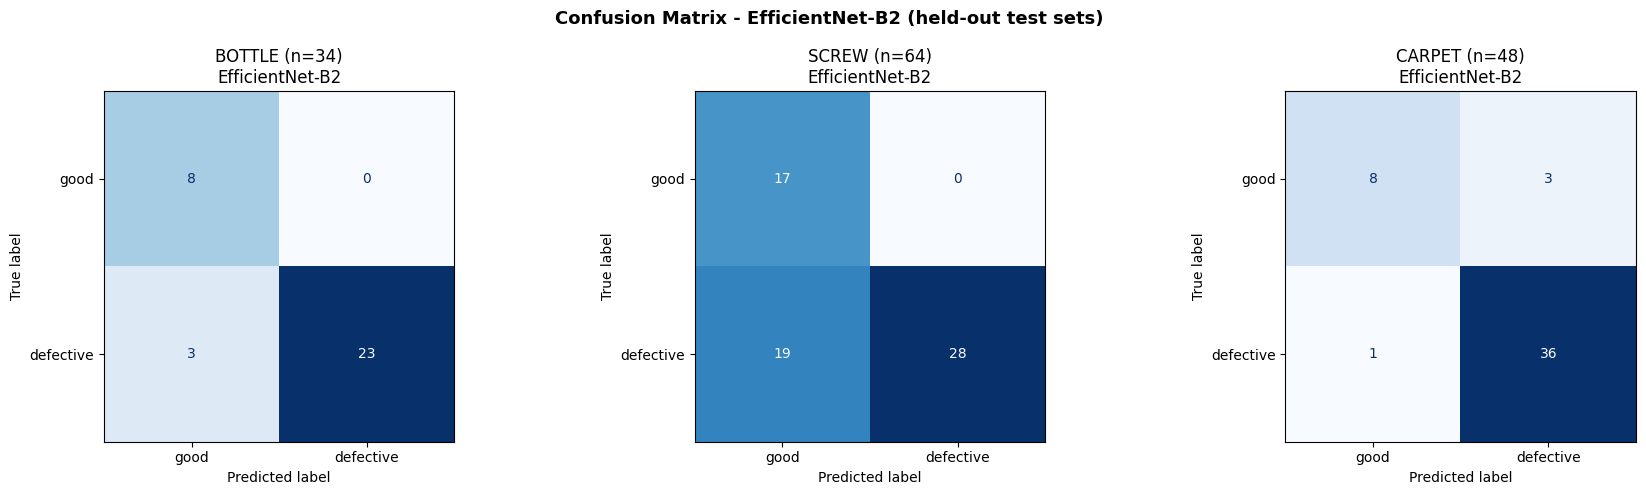

Confusion matrix saved as confusion_matrix_v2.png


In [27]:
# Confusion Matrix (clean test sets)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, cat in enumerate(CATEGORIES):
    cm = confusion_matrix(
        eval_results[cat]["labels"],
        eval_results[cat]["preds"],
        labels=[0, 1]                       
    )
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_NAMES
    )
    disp.plot(ax=axes[i], colorbar=False, cmap="Blues")

    n = len(eval_results[cat]["labels"])
    axes[i].set_title(f"{cat.upper()} (n={n})\nEfficientNet-B2")

plt.suptitle(
    "Confusion Matrix - EfficientNet-B2 (held-out test sets)",
    fontsize=13, fontweight="bold"
)
plt.tight_layout()
plt.savefig("confusion_matrix_v2.png", dpi=100, bbox_inches="tight")
plt.show()
print("Confusion matrix saved as confusion_matrix_v2.png")

### Classification Report (Test Set)

Per-class precision, recall and F1 on the held-out test sets.
Read alongside the confusion matrix: recall on the defective class
is the primary metric.

In [28]:
# Classification Report
for cat in CATEGORIES:
    print(f"\n{cat.upper()} - Classification Report (test, n={len(eval_results[cat]['labels'])})")
    print("=" * 55)
    print(classification_report(
        eval_results[cat]["labels"],
        eval_results[cat]["preds"],
        target_names=CLASS_NAMES,
        zero_division=0
    ))


BOTTLE - Classification Report (test, n=34)
              precision    recall  f1-score   support

        good       0.73      1.00      0.84         8
   defective       1.00      0.88      0.94        26

    accuracy                           0.91        34
   macro avg       0.86      0.94      0.89        34
weighted avg       0.94      0.91      0.92        34


SCREW - Classification Report (test, n=64)
              precision    recall  f1-score   support

        good       0.47      1.00      0.64        17
   defective       1.00      0.60      0.75        47

    accuracy                           0.70        64
   macro avg       0.74      0.80      0.69        64
weighted avg       0.86      0.70      0.72        64


CARPET - Classification Report (test, n=48)
              precision    recall  f1-score   support

        good       0.89      0.73      0.80        11
   defective       0.92      0.97      0.95        37

    accuracy                           0.92     

## Results & Limitations

### Final results (held-out test sets, single evaluation)
| Category | Test n | Accuracy | Recall | Precision | F1 | AUC |
|---|---|---|---|---|---|---|
| Bottle | 34 | 91.18% | 88.46% | 100% | 93.88% | 1.000 |
| Screw | 64 | 70.31% | 59.57% | 100% | 74.67% | 0.973 |
| Carpet | 48 | 91.67% | 97.30% | 92.31% | 94.74% | 0.961 |

Missed defects: bottle 3 of 26, screw 19 of 47, carpet 1 of 37.

### Key findings
- Transfer learning (EfficientNet-B2) learned useful features. A CNN from
  scratch did not learn from ~25 defective training images.
- **Carpet** is closest to the recall target (0.95). **Bottle** is near it.
  **Screw** misses it (recall 0.60) and is not production-ready.
- Bottle and screw have no false alarms but miss borderline defects. Screw
  AUC is 0.97, so a lower decision threshold chosen on validation data is a
  promising next step.

### Leakage found and fixed
An earlier version trained on test-folder defects and was evaluated on the
same folder, inflating results (e.g. screw ~99%). Everything was retrained
on a stratified train / validation / test split with an overlap assertion.
The numbers above are the corrected ones.

### Limitations
- **Small test sets** (34 / 64 / 48 images): one image moves a metric by
  2-3%, and confidence intervals are wide. Bottle AUC of 1.000 is on 8
  normal images only.
- **Not the standard MVTec protocol.** The benchmark trains on good images
  only. This project also trains on 40% of the test-folder images, including
  defects, so results are not comparable with published anomaly-detection scores.
- One configuration per category, final-epoch models, no tuning on test data.
- Three categories only (bottle, screw, carpet), one model per category.
- Class imbalance (~10:1) handled with class weights only.

### Future work
Validation chosen decision threshold, more defective training data,
PatchCore for fine grained defects such as screw scratches.

*Academic project. Not validated for production use.*

## Improve: Training Curves

Train and validation loss/accuracy per epoch for each category,
taken from the training logs (validation only, no test data).

Used to check overfitting. Validation sets are small (16 to 32 images),
so curves are noisy and no epoch is selected from them.

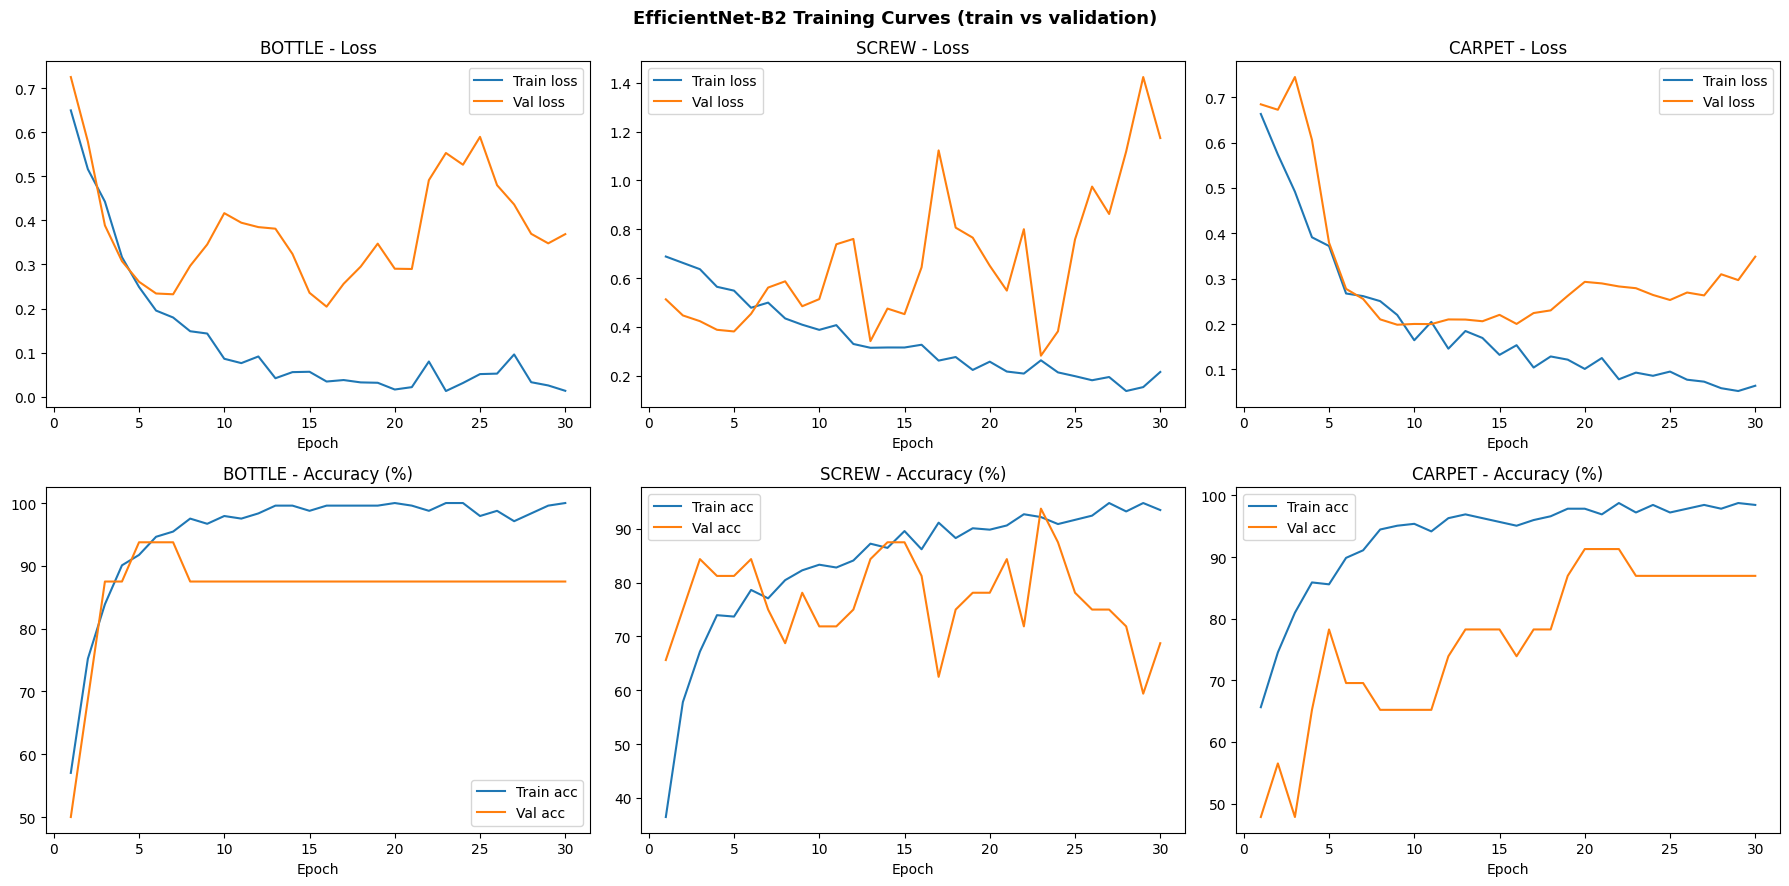

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))

for i, cat in enumerate(CATEGORIES):
    h = effnet_histories[cat]
    epochs = range(1, len(h["train_losses"]) + 1)

    axes[0, i].plot(epochs, h["train_losses"], label="Train loss")
    axes[0, i].plot(epochs, h["test_losses"], label="Val loss")   
    axes[0, i].set_title(f"{cat.upper()} - Loss")
    axes[0, i].set_xlabel("Epoch")
    axes[0, i].legend()

    axes[1, i].plot(epochs, h["train_accs"], label="Train acc")
    axes[1, i].plot(epochs, h["test_accs"], label="Val acc")
    axes[1, i].set_title(f"{cat.upper()} - Accuracy (%)")
    axes[1, i].set_xlabel("Epoch")
    axes[1, i].legend()

plt.suptitle("EfficientNet-B2 Training Curves (train vs validation)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("training_curves_v2.png", dpi=100, bbox_inches="tight")
plt.show()

### Training Curves: Findings

**Loss:** Train loss falls steadily in all categories, while validation loss bottoms out early (bottle ~epoch 7, carpet ~epochs 8-11) and then rises, which indicates overfitting. Screw validation loss is very noisy (32 images).

**Accuracy:**
| Category | Train | Validation | Reading |
|---|---|---|---|
| Bottle | ~100% | plateaus at 87.5% (14/16) from epoch 8 | Mild overfitting |
| Screw | ~93% | swings 59-94%, no trend | Unstable, matches weak test recall |
| Carpet | ~98% | improves to ~87-91% | Most stable |

**Notes:** Final-epoch models were evaluated and no epoch was selected from these curves. Validation sets are tiny (16-32 images), so conclusions are tentative. Possible improvements: early stopping on validation loss, stronger augmentation, more defective training data.

##  Save & Reload 

Reload the saved `_v2` models from disk into fresh EfficientNet-B2 objects and
check that they give identical outputs to the trained models. This is the same
loading path the FastAPI app will use.

In [34]:
# Save and Reload
loaded_models = {}

for cat in CATEGORIES:
    m = efficientnet_b2(weights=None).to(device)
    in_features = m.classifier[1].in_features
    m.classifier = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(in_features, NUM_CLASSES)
    ).to(device)

    m.load_state_dict(torch.load(MODEL_DIR / f"effnet_{cat}_v2.pth",
                                map_location=device))
    m.eval()
    loaded_models[cat] = m

    # Verify
    x, _ = next(iter(test_loaders[cat]))
    x = x.to(device)
    effnet_models[cat].eval()
    with torch.no_grad():
        same = torch.allclose(effnet_models[cat](x), m(x), atol=1e-5)
    print(f"{cat}: reloaded model matches original -> {same}")    

bottle: reloaded model matches original -> True
screw: reloaded model matches original -> True
carpet: reloaded model matches original -> True


## Conclusion & Limitations

### Summary
Binary defect detection (normal vs defective) on three MVTec AD categories
(bottle, screw, carpet) using one EfficientNet-B2 transfer-learning model per
category, trained on AWS SageMaker (Tesla T4) and served with FastAPI.

### Final results (held-out test sets, single evaluation)
| Category | Test n | Recall | Precision | F1 | AUC | Missed defects |
|---|---|---|---|---|---|---|
| Bottle | 34 | 88.5% | 100% | 93.9% | 1.000 | 3 of 26 |
| Screw | 64 | 59.6% | 100% | 74.7% | 0.973 | 19 of 47 |
| Carpet | 48 | 97.3% | 92.3% | 94.7% | 0.961 | 1 of 37 |

### Key findings
- A CNN from scratch did not learn from ~25 defective training images;
  pretrained EfficientNet-B2 did.
- Carpet meets the 0.95 recall target, bottle is close, screw is not
  production-ready (recall 0.60 despite AUC 0.97, so the 0.5 threshold is
  too conservative; a validation-chosen threshold is future work).
- Models overfit after ~7-10 epochs; final-epoch models were evaluated.

### Data leakage found and fixed
An earlier version trained on test-folder defects and was evaluated on the same
folder (screw ~99%). All models were retrained on a stratified
train/validation/test split with an overlap assertion. The numbers above are
the corrected ones.

### Limitations
- Small test sets (34/64/48 images): one image moves a metric 2-3%, intervals are wide
- Not the standard MVTec protocol (which trains on good images only), so
  results are not comparable with published anomaly-detection scores
- One configuration per category, no tuning on test data
- Three categories only; class imbalance handled with class weights only
- `torch.compile()` was not used (cuDNN loading error on the instance, resolved by disabling cuDNN)

### Future work
Validation-chosen threshold, early stopping, more defective data, PatchCore for
fine-grained defects, Grad-CAM to inspect what the models look at.

*Academic project. Not validated for production use.*

##  FastAPI Inference API

REST API that serves the three saved EfficientNet-B2 models (`_v2`).

| Endpoint | Purpose |
|---|---|
| `GET /health` | Check the API is running |
| `POST /predict/{category}` | Upload an image (`bottle`, `screw` or `carpet`), get Normal/Defective plus the defect probability |

- One model per category, loaded once at startup, CPU inference
- Same preprocessing as evaluation (224x224, ImageNet normalisation)
- Decision threshold 0.5. Screw responses carry a warning (test recall 0.60)
- Academic demo, not validated for production use

In [35]:
# Create the project folder
import os, shutil

os.makedirs("anomaly_api/models", exist_ok=True)
for cat in CATEGORIES:
    shutil.copy(MODEL_DIR / f"effnet_{cat}_v2.pth", "anomaly_api/models/")

with open("anomaly_api/requirements.txt", "w") as f:
    f.write("fastapi\nuvicorn\npython-multipart\ntorch\ntorchvision\npillow\n")

print(os.listdir("anomaly_api"), os.listdir("anomaly_api/models"))

['models', 'requirements.txt'] ['effnet_screw_v2.pth', 'effnet_bottle_v2.pth', 'effnet_carpet_v2.pth']


In [37]:
# Create app.py
app_code = '''import io
from pathlib import Path

import torch
import torch.nn as nn
from fastapi import FastAPI, File, HTTPException, UploadFile
from PIL import Image
from torchvision import transforms
from torchvision.models import efficientnet_b2

MODEL_DIR = Path(__file__).parent / "models"
CATEGORIES = ["bottle", "screw", "carpet"]
DEVICE = "cpu"

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

def build_model():
    m = efficientnet_b2(weights=None)
    m.classifier = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(m.classifier[1].in_features, 2),
    )
    return m

models = {}
for cat in CATEGORIES:
    m = build_model()
    m.load_state_dict(torch.load(MODEL_DIR / f"effnet_{cat}_v2.pth",
                                 map_location=DEVICE))
    m.eval()
    models[cat] = m

app = FastAPI(title="Industrial Anomaly Detection API", version="1.0.0")

@app.get("/health")
def health():
    return {"status": "ok", "categories": CATEGORIES}

@app.post("/predict/{category}")
async def predict(category: str, file: UploadFile = File(...)):
    if category not in models:
        raise HTTPException(404, f"category must be one of {CATEGORIES}")
    try:
        img = Image.open(io.BytesIO(await file.read())).convert("RGB")
    except Exception:
        raise HTTPException(400, "could not read the file as an image")

    x = transform(img).unsqueeze(0)
    with torch.no_grad():
        probs = torch.softmax(models[category](x), dim=1)[0]
    p_defect = float(probs[1])

    result = {
        "category": category,
        "prediction": "defective" if p_defect >= 0.5 else "normal",
        "defect_probability": round(p_defect, 4),
    }
    if category == "screw":
        result["warning"] = ("Screw model missed many defects in testing "
                             "(recall 0.60). Demo only.")
    return result
'''

with open("anomaly_api/app.py", "w") as f:
    f.write(app_code)
print("app.py written:", len(app_code), "characters")

app.py written: 1993 characters


In [38]:
!pip install fastapi httpx python-multipart --quiet

import sys
sys.path.insert(0, "anomaly_api")
from fastapi.testclient import TestClient
from app import app as api_app

client = TestClient(api_app)
print(client.get("/health").json())

for cat in CATEGORIES:
    ds = test_datasets[cat]
    for want, name in [(0, "normal"), (1, "defective")]:
        path = next(p for p, l in zip(ds.images, ds.labels) if l == want)
        with open(path, "rb") as f:
            r = client.post(f"/predict/{cat}", files={"file": f})
        print(f"{cat:7s} actual={name:9s} ->", r.json())

# Error handling checks
print(client.post("/predict/cable", files={"file": ("x.png", b"abc")}).status_code)      # expect 404
print(client.post("/predict/bottle", files={"file": ("x.txt", b"not an image")}).status_code)  # expect 400

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


{'status': 'ok', 'categories': ['bottle', 'screw', 'carpet']}
bottle  actual=normal    -> {'category': 'bottle', 'prediction': 'normal', 'defect_probability': 0.0067}
bottle  actual=defective -> {'category': 'bottle', 'prediction': 'defective', 'defect_probability': 0.9974}
screw   actual=normal    -> {'category': 'screw', 'prediction': 'normal', 'defect_probability': 0.0099, 'warning': 'Screw model missed many defects in testing (recall 0.60). Demo only.'}
screw   actual=defective -> {'category': 'screw', 'prediction': 'normal', 'defect_probability': 0.1578, 'warning': 'Screw model missed many defects in testing (recall 0.60). Demo only.'}
carpet  actual=normal    -> {'category': 'carpet', 'prediction': 'normal', 'defect_probability': 0.1097}
carpet  actual=defective -> {'category': 'carpet', 'prediction': 'defective', 'defect_probability': 0.7249}
404
400


In [ ]:
# Readme